# Benchmark: fit time, memory and API effort

This study asks how fit time and peak memory grow with the number of rows
for each method at fixed settings, and how much code each library needs for
ten common modelling tasks, from fitting a tuned model to predicting a
standard deviation. A user choosing a library for a large data set, or for a
task such as an effect with an interval, needs both. The code counts come
from recipes that were executed on the installed library versions.

:::{admonition} What this study estimates
:class: dropdown

| | |
|---|---|
| **Target** | how fit time and peak memory grow with the number of rows, and how much code ten common tasks need in each library |
| **Observed response** | a simulated continuous response; a small simulated frame for the API recipes |
| **Estimand** | median single-threaded fit time and peak resident memory at fixed settings; the number of lines and library names each executed recipe needs |
| **Units** | seconds, megabytes, lines of code |
| **Sampling unit** | one fit at a given row count; one recipe per task and library |
| **Dependence** | independent fits, each in its own process |
| **Split / resampling unit** | no split: fit time on the training rows only |
| **Tuning** | none: fixed settings (500 steps, rounds or iterations) so that time measures the algorithm, not a search |
| **Uncertainty** | median of three fits with the minimum and maximum up to 10^5 rows; a single fit at 10^6; the recipe counts are exact |
| **Claim type** | descriptive: costs on this machine |
:::

## Summary of results

The table gives, for each library, the fit time and peak memory of the
largest fixed-setting fit it completed and how many of the ten modelling
tasks it supports natively, with the code they take.

In [1]:
import json
from pathlib import Path

import altair as alt
import numpy as np
import polars as pl

from bench_tables import table as annotated

scaling_rows = pl.DataFrame([r for r in json.loads(Path("bench_scaling.json").read_text())["results"]
                             if "seconds" in r and "error" not in r and not r.get("timeout")],
                            infer_schema_length=None)
api_rows = pl.DataFrame(json.loads(Path("bench_api_friction.json").read_text())["results"],
                        infer_schema_length=None)
at_size = lambda n, column, name: (scaling_rows.filter(pl.col("n") == n)
                                   .select("method", pl.col(column).alias(name)))
effort = (api_rows.group_by("library")
          .agg((pl.col("label") == "native").sum().alias("native"),
               (pl.col("label") == "unsupported").sum().alias("unsupported"),
               pl.col("lines").sum().alias("lines"))
          .with_columns(pl.col("native", "unsupported", "lines").cast(pl.Float64)))

In [2]:
overview = (at_size(100_000, "seconds", "s_1e5")
            .join(at_size(1_000_000, "seconds", "s_1e6"), on="method", how="full", coalesce=True)
            .join(at_size(1_000_000, "peak_mb", "mb_1e6"), on="method", how="full", coalesce=True)
            .with_columns(pl.col("method").str.split(" ").list.first().alias("library"))
            .join(effort, on="library", how="full", coalesce=True)
            .with_columns(pl.coalesce("method", "library").alias("method"))
            .drop("library")
            .sort("s_1e6", nulls_last=True))

In [3]:
annotated(
    overview.select("method", "s_1e5", "s_1e6", "mb_1e6", "native", "unsupported", "lines"),
    title="Fit time, memory and API effort by library",
    subtitle="Fixed-setting fits on one thread; ten executed API recipes per library",
    spanners={"Seconds per fit ↓": ["s_1e5", "s_1e6"],
              "API, of 10 tasks": ["native", "unsupported", "lines"]},
    labels={"s_1e5": "10^5 rows", "s_1e6": "10^6 rows", "mb_1e6": "MB at 10^6 ↓",
            "native": "native ↑", "unsupported": "unsupported ↓", "lines": "lines ↓"},
    better={"s_1e5": "min", "s_1e6": "min", "mb_1e6": "min", "native": "max",
            "unsupported": "min", "lines": "min"},
    formats={"s_1e5": 1, "s_1e6": 1, "mb_1e6": 0, "native": 0, "unsupported": 0, "lines": 0},
    notes=["Seconds: median single-threaded fit at fixed settings with no tuning. MB: peak "
           "resident memory of that fit at 10^6 rows. native: tasks the library supports "
           "directly; unsupported: tasks it has no path for; lines: code over all ten "
           "recipes, imports excluded. mboostrs binned shares the mboostrs API row. – : "
           "not run at that size, or not part of that measurement (NGBoost was not in the "
           "scaling runs). Bold: best in the column. Sources: bench_scaling.json and "
           "bench_api_friction.json."])

GT(_tbl_data=shape: (9, 7)
┌─────────────────┬───────────┬────────────┬─────────────┬────────┬─────────────┬───────┐
│ method          ┆ s_1e5     ┆ s_1e6      ┆ mb_1e6      ┆ native ┆ unsupported ┆ lines │
│ ---             ┆ ---       ┆ ---        ┆ ---         ┆ ---    ┆ ---         ┆ ---   │
│ str             ┆ f64       ┆ f64        ┆ f64         ┆ f64    ┆ f64         ┆ f64   │
╞═════════════════╪═══════════╪════════════╪═════════════╪════════╪═════════════╪═══════╡
│ mgcv            ┆ 128.38    ┆ 2.004      ┆ 1175.1875   ┆ 9.0    ┆ 1.0         ┆ 14.0  │
│ mboostrs        ┆ 0.571686  ┆ 4.891553   ┆ 3406.953125 ┆ 10.0   ┆ 0.0         ┆ 17.0  │
│ mboostrs binned ┆ 0.635407  ┆ 5.541031   ┆ 632.703125  ┆ 10.0   ┆ 0.0         ┆ 17.0  │
│ XGBoost         ┆ 1.243713  ┆ 8.08132    ┆ 345.015625  ┆ 7.0    ┆ 1.0         ┆ 23.0  │
│ LightGBM        ┆ 1.236016  ┆ 8.227842   ┆ 345.640625  ┆ 7.0    ┆ 1.0         ┆ 21.0  │
│ CatBoost        ┆ 4.028058  ┆ 29.811329  ┆ 589.515625  ┆ 9.0    ┆ 1.0         ┆ 16.0  │
│ EBM             ┆ 23.885496 ┆ 413.318295 ┆ 797.296875  ┆ 8.0    ┆ 1.0         ┆ 15.0  │
│ APLR            ┆ 89.403182 ┆ 1080.23422 ┆ 661.4375    ┆ 6.0    ┆ 2.0         ┆ 19.0  │
│ NGBoost         ┆ null      ┆ null       ┆ null        ┆ 5.0    ┆ 4.0         ┆ 12.0  │
└─────────────────┴───────────┴────────────┴─────────────┴────────┴─────────────┴───────┘, _body=<great_tables._gt_data.Body object at 0x10ae94890>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='s_1e5', type=<ColInfoTypeEnum.default: 1>, column_label='10^5 rows', column_align='right', column_width=None, stub_level=None), ColInfo(var='s_1e6', type=<ColInfoTypeEnum.default: 1>, column_label='10^6 rows', column_align='right', column_width=None, stub_level=None), ColInfo(var='mb_1e6', type=<ColInfoTypeEnum.default: 1>, column_label='MB at 10^6 ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='native', type=<ColInfoTypeEnum.default: 1>, column_label='native ↑', column_align='right', column_width=None, stub_level=None), ColInfo(var='unsupported', type=<ColInfoTypeEnum.default: 1>, column_label='unsupported ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='lines', type=<ColInfoTypeEnum.default: 1>, column_label='lines ↓', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10960a030>, _spanners=Spanners([SpannerInfo(spanner_id='Seconds per fit ↓', spanner_level=0, spanner_label='Seconds per fit ↓', spanner_units=None, spanner_pattern=None, vars=['s_1e5', 's_1e6'], built=None), SpannerInfo(spanner_id='API, of 10 tasks', spanner_level=0, spanner_label='API, of 10 tasks', spanner_units=None, spanner_pattern=None, vars=['native', 'unsupported', 'lines'], built=None)]), _heading=Heading(title='Fit time, memory and API effort by library', subtitle='Fixed-setting fits on one thread; ten executed API recipes per library', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10aefce00>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x1092cca40>, _source_notes=['Seconds: median single-threaded fit at fixed settings with no tuning. MB: peak resident memory of that fit at 10^6 rows. native: tasks the library supports directly; unsupported: tasks it has no path for; lines: code over all ten recipes, imports excluded. mboostrs binned shares the mboostrs API row. – : not run at that size, or not part of that measurement (NGBoost was not in the scaling runs). Bold: best in the column. Sources: bench_scaling.json and bench_api_friction.json.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10A881730>, mask=None), grpname=None, colname='s_1e5', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(colu

## Fit time and memory

The scaling runs fit the additive task of [](benchmark_insight.ipynb) (ten
features, five with signal) at $10^3$ to $10^6$ rows with fixed settings and
no tuning. The methods are:

- mboostrs: 500 boosting steps over one `bbs(x, df=4)` term per feature (a
  P-spline, a cubic B-spline basis with 24 columns and a penalty on
  differences of adjacent coefficients, held to 4 effective degrees of
  freedom). The exact route uses every row's value of each feature; the
  binned route (`bins=256`) replaces each feature by at most 256 distinct
  values and evaluates the basis only at those values;
- the Explainable Boosting Machine (EBM, from InterpretML) without pair
  terms (`interactions=0`);
- APLR (automatic piecewise linear regression) without pair terms and with
  $m=500$ boosting steps;
- gradient-boosted tree libraries: XGBoost with 500 rounds of depth-4 trees, LightGBM with 500 rounds of
  15-leaf trees, and CatBoost with 500 depth-6 iterations;
- the R package mgcv: `gam` with REML (restricted maximum likelihood)
  smoothness selection up to $10^5$ rows, and `bam` with `discrete=TRUE` at
  $10^6$.

Each fit runs in its own process on one thread; the time is the median of
three fits up to $10^5$ rows and a single fit at $10^6$. A method is not run
at a larger size once a fit takes more than ten minutes. Results were
measured with mboostrs 0.1.3.

In [4]:
scaling = json.loads(Path("bench_scaling.json").read_text())
scale = pl.DataFrame([r for r in scaling["results"] if "seconds" in r and "error" not in r
                      and not r.get("timeout")], infer_schema_length=None)
stopped = [(r["method"], r["n"]) for r in scaling["results"]
           if r.get("skipped") or r.get("timeout") or "error" in r]
wide = (scale.select("method", "n", "seconds")
        .pivot(on="n", index="method", values="seconds")
        .rename(lambda c: c if c == "method" else f"n={int(c):,}"))
sizes = [c for c in wide.columns if c != "method"]
display(annotated(
    wide.sort(sizes[-1], nulls_last=True),
    title="Fit time by number of rows, fixed settings",
    subtitle="Median seconds of one single-threaded fit; ten features, five with signal",
    better={c: "min" for c in sizes}, decimals=2,
    notes=["Each method runs at fixed settings with no tuning (500 boosting steps or "
           "rounds, or mgcv's REML fit), so a tuned fit multiplies these times by the size "
           "of its search. mboostrs binned: the same fit with each feature binned into 256 "
           "values. – : not run at that size (mgcv's gam above 10^5 rows, where bam is "
           "used) or stopped by the time limit. Bold: fastest at each size. Source: "
           "bench_scaling.json."]))

GT(_tbl_data=shape: (8, 5)
┌─────────────────┬──────────┬───────────┬───────────┬─────────────┐
│ method          ┆ n=1,000  ┆ n=10,000  ┆ n=100,000 ┆ n=1,000,000 │
│ ---             ┆ ---      ┆ ---       ┆ ---       ┆ ---         │
│ str             ┆ f64      ┆ f64       ┆ f64       ┆ f64         │
╞═════════════════╪══════════╪═══════════╪═══════════╪═════════════╡
│ mgcv            ┆ 1.297    ┆ 36.174    ┆ 128.38    ┆ 2.004       │
│ mboostrs        ┆ 0.108272 ┆ 0.151419  ┆ 0.571686  ┆ 4.891553    │
│ mboostrs binned ┆ 0.135638 ┆ 0.181891  ┆ 0.635407  ┆ 5.541031    │
│ XGBoost         ┆ 0.659713 ┆ 0.73065   ┆ 1.243713  ┆ 8.08132     │
│ LightGBM        ┆ 0.617491 ┆ 0.682701  ┆ 1.236016  ┆ 8.227842    │
│ CatBoost        ┆ 1.31877  ┆ 1.572079  ┆ 4.028058  ┆ 29.811329   │
│ EBM             ┆ 2.348994 ┆ 3.780585  ┆ 23.885496 ┆ 413.318295  │
│ APLR            ┆ 4.609527 ┆ 11.721759 ┆ 89.403182 ┆ 1080.23422  │
└─────────────────┴──────────┴───────────┴───────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x1094d2f30>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='n=1,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=1,000', column_align='right', column_width=None, stub_level=None), ColInfo(var='n=10,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=10,000', column_align='right', column_width=None, stub_level=None), ColInfo(var='n=100,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=100,000', column_align='right', column_width=None, stub_level=None), ColInfo(var='n=1,000,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=1,000,000', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10af75af0>, _spanners=Spanners([]), _heading=Heading(title='Fit time by number of rows, fixed settings', subtitle='Median seconds of one single-threaded fit; ten features, five with signal', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10af765a0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10af764e0>, _source_notes=["Each method runs at fixed settings with no tuning (500 boosting steps or rounds, or mgcv's REML fit), so a tuned fit multiplies these times by the size of its search. mboostrs binned: the same fit with each feature binned into 256 values. – : not run at that size (mgcv's gam above 10^5 rows, where bam is used) or stopped by the time limit. Bold: fastest at each size. Source: bench_scaling.json."], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AF767E0>, mask=None), grpname=None, colname='n=1,000', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AF767E0>, mask=None), grpname=None, colname='n=1,000', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AF767E0>, mask=None), grpname=None, colname='n=10,000', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AF767E0>, mask=None), grpname=None, colname='n=10,000', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AF767E0>, mask=None), grpname=None, colname='n=100,000', rownum=1, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10AF767E0>, mask=None), grpname=None, colname='n=100,000', rownum=2, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("met

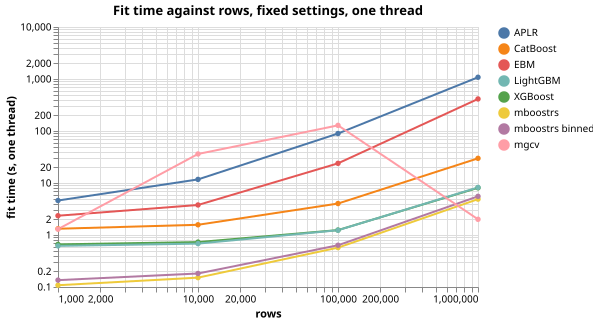

In [5]:
alt.Chart(scale).mark_line(point=True).encode(
    x=alt.X("n:Q", scale=alt.Scale(type="log"), title="rows"),
    y=alt.Y("seconds:Q", scale=alt.Scale(type="log"), title="fit time (s, one thread)"),
    color=alt.Color("method:N", title=None),
).properties(width=420, height=260, title="Fit time against rows, fixed settings, one thread")

In [6]:
memory = (scale.select("method", "n", "peak_mb")
          .pivot(on="n", index="method", values="peak_mb")
          .rename(lambda c: c if c == "method" else f"n={int(c):,}"))
display(annotated(
    memory.sort(sizes[-1], nulls_last=True),
    title="Peak memory by number of rows, fixed settings",
    subtitle="Peak resident memory of the fitting process, in megabytes",
    better={c: "min" for c in sizes}, decimals=0,
    notes=["Peak resident set size of the process that ran one fit, including the "
           "interpreter and the data. Bold: least at each size."]))


def at(method, n, column="seconds"):
    rows = scale.filter((pl.col("method") == method) & (pl.col("n") == n))
    return rows[column][0] if rows.height else float("nan")


largest = int(scale["n"].max())
mb_exact_big = at("mboostrs", 100_000)
mb_exact_largest = at("mboostrs", largest)
mb_binned_big = at("mboostrs binned", largest)
lgbm_big = at("LightGBM", largest)
mb_exact_mem = at("mboostrs", largest, "peak_mb")
mb_binned_mem = at("mboostrs binned", largest, "peak_mb")
mgcv_big = at("mgcv", largest)

GT(_tbl_data=shape: (8, 5)
┌─────────────────┬────────────┬────────────┬────────────┬─────────────┐
│ method          ┆ n=1,000    ┆ n=10,000   ┆ n=100,000  ┆ n=1,000,000 │
│ ---             ┆ ---        ┆ ---        ┆ ---        ┆ ---         │
│ str             ┆ f64        ┆ f64        ┆ f64        ┆ f64         │
╞═════════════════╪════════════╪════════════╪════════════╪═════════════╡
│ XGBoost         ┆ 176.796875 ┆ 178.09375  ┆ 191.890625 ┆ 345.015625  │
│ LightGBM        ┆ 174.15625  ┆ 175.828125 ┆ 197.96875  ┆ 345.640625  │
│ CatBoost        ┆ 239.125    ┆ 242.109375 ┆ 269.953125 ┆ 589.515625  │
│ mboostrs binned ┆ 74.953125  ┆ 77.84375   ┆ 110.65625  ┆ 632.703125  │
│ APLR            ┆ 105.53125  ┆ 113.53125  ┆ 159.296875 ┆ 661.4375    │
│ EBM             ┆ 182.328125 ┆ 184.46875  ┆ 225.609375 ┆ 797.296875  │
│ mgcv            ┆ 292.015625 ┆ 752.75     ┆ 1806.03125 ┆ 1175.1875   │
│ mboostrs        ┆ 76.953125  ┆ 108.03125  ┆ 411.203125 ┆ 3406.953125 │
└─────────────────┴────────────┴────────────┴────────────┴─────────────┘, _body=<great_tables._gt_data.Body object at 0x1094d2f30>, _boxhead=Boxhead([ColInfo(var='method', type=<ColInfoTypeEnum.stub: 2>, column_label='method', column_align='left', column_width=None, stub_level=0), ColInfo(var='n=1,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=1,000', column_align='right', column_width=None, stub_level=None), ColInfo(var='n=10,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=10,000', column_align='right', column_width=None, stub_level=None), ColInfo(var='n=100,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=100,000', column_align='right', column_width=None, stub_level=None), ColInfo(var='n=1,000,000', type=<ColInfoTypeEnum.default: 1>, column_label='n=1,000,000', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x10af47020>, _spanners=Spanners([]), _heading=Heading(title='Peak memory by number of rows, fixed settings', subtitle='Peak resident memory of the fitting process, in megabytes', preheader=None), _stubhead='Method', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b28d040>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b28ce60>, _source_notes=['Peak resident set size of the process that ran one fit, including the interpreter and the data. Bold: least at each size.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B28D250>, mask=None), grpname=None, colname='n=1,000', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B28D250>, mask=None), grpname=None, colname='n=1,000', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B28D250>, mask=None), grpname=None, colname='n=10,000', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B28D250>, mask=None), grpname=None, colname='n=10,000', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B28D250>, mask=None), grpname=None, colname='n=100,000', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B28D250>, mask=None), grpname=None, colname='n=100,000', rownum=7, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.starts_with(…'] at 0x10B28D250>, mask=None), grpname=None, colname='n=1,000,000', rownum=3, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("method").str.start

At $10^5$ rows the exact `gamboost` fit takes {eval}`round(mb_exact_big, 1)`
seconds. At {eval}`f"{largest:,}"` rows the exact fit takes
{eval}`round(mb_exact_largest, 1)` seconds and the binned route
{eval}`round(mb_binned_big, 1)` seconds, against {eval}`round(lgbm_big, 1)` for
LightGBM and {eval}`round(at("XGBoost", largest), 1)` for XGBoost, the fastest
tree libraries here, and {eval}`round(mgcv_big, 1)` for mgcv's `bam` with
`discrete=TRUE`, which discretizes the covariates for the same reason (the
drop in mgcv's line at $10^6$ is the switch from `gam` to `bam`). Binning
replaces the $n$ rows by at most 256 distinct values per feature, so the cost
of evaluating a learner at each step depends on the number of bins rather
than on $n$. Memory is where the exact route falls behind: at
{eval}`f"{largest:,}"` rows it peaks at
{eval}`round(mb_exact_mem / 1024, 1)` GB, because each prepared spline learner
keeps its $n \times 24$ design (1.9 GB for ten terms at this size), while the
binned route keeps a 256-row basis and one bin index per row and peaks at
{eval}`round(mb_binned_mem)` MB. `autospec` (the function that proposes a formula from the data) recommends `bins=256` above
$10^5$ rows. {eval}`"Every method completed every size within the ten-minute limit." if not stopped else "Sizes not completed within ten minutes: " + ", ".join(f"{m} at {n:,}" for m, n in stopped) + "."`

## API effort for ten tasks

For each library, a recipe is the shortest code for a task that could be
written from the library's documentation; each recipe was executed on the
same small data set (500 rows, four numeric features, predictions on 50 new
rows), so every counted recipe runs. A recipe is **native** when the
library provides the capability, **composed** when it has to be assembled
from several outputs or a second package, and **unsupported** when there is
no path. Lines exclude imports; "names" counts the distinct library
functions and attributes a recipe uses.

In [7]:
api = json.loads(Path("bench_api_friction.json").read_text())
recipes = pl.DataFrame(api["results"], infer_schema_length=None)
tasks = list(api["tasks"])
label = {"native": "N", "composed": "C", "unsupported": "-"}
matrix = (recipes.with_columns(
              pl.when(pl.col("label") == "unsupported").then(pl.lit("-"))
              .otherwise(pl.col("label").replace_strict(label) + pl.col("lines").cast(pl.Utf8))
              .alias("cell"))
          .pivot(on="library", index="task", values="cell")
          .with_columns(pl.col("task").replace_strict({t: i for i, t in enumerate(tasks)}).alias("o"))
          .sort("o").drop("o"))
display(annotated(
    matrix, stub="task", stubhead="Task",
    title="Ten modelling tasks: how each library does them",
    subtitle="N: native, C: composed from several outputs or packages, –: unsupported; "
             "the number is the lines of code",
    notes=["Each recipe is the shortest code written from the library's documentation and "
           "was executed on the same small data. Lines exclude imports. Tasks: " +
           "; ".join(f"{k}: {v}" for k, v in api["tasks"].items()) + "."]))

GT(_tbl_data=shape: (10, 9)
┌─────────────┬──────────┬─────┬──────┬───┬──────────┬──────────┬─────────┬──────┐
│ task        ┆ mboostrs ┆ EBM ┆ APLR ┆ … ┆ LightGBM ┆ CatBoost ┆ NGBoost ┆ mgcv │
│ ---         ┆ ---      ┆ --- ┆ ---  ┆   ┆ ---      ┆ ---      ┆ ---     ┆ ---  │
│ str         ┆ str      ┆ str ┆ str  ┆   ┆ str      ┆ str      ┆ str     ┆ str  │
╞═════════════╪══════════╪═════╪══════╪═══╪══════════╪══════════╪═════════╪══════╡
│ fit_tuned   ┆ N2       ┆ N2  ┆ N3   ┆ … ┆ N4       ┆ N4       ┆ N4      ┆ N1   │
│ effect      ┆ N1       ┆ N1  ┆ N2   ┆ … ┆ N1       ┆ N1       ┆ -       ┆ N1   │
│ effect_band ┆ N2       ┆ C4  ┆ -    ┆ … ┆ -        ┆ -        ┆ -       ┆ N2   │
│ importance  ┆ N1       ┆ N1  ┆ N1   ┆ … ┆ N1       ┆ N1       ┆ N1      ┆ N1   │
│ interaction ┆ N2       ┆ N2  ┆ C2   ┆ … ┆ C5       ┆ N2       ┆ -       ┆ -    │
│ probability ┆ N2       ┆ N2  ┆ N3   ┆ … ┆ N2       ┆ N2       ┆ N2      ┆ N2   │
│ variance    ┆ N3       ┆ -   ┆ -    ┆ … ┆ C3       ┆ N2       ┆ N2      ┆ N2   │
│ categorical ┆ N1       ┆ N1  ┆ C4   ┆ … ┆ N2       ┆ N1       ┆ C2      ┆ N2   │
│ missing     ┆ N1       ┆ N1  ┆ N3   ┆ … ┆ N1       ┆ N1       ┆ -       ┆ N1   │
│ save_load   ┆ N2       ┆ N1  ┆ N1   ┆ … ┆ N2       ┆ N2       ┆ N1      ┆ N2   │
└─────────────┴──────────┴─────┴──────┴───┴──────────┴──────────┴─────────┴──────┘, _body=<great_tables._gt_data.Body object at 0x10b28f770>, _boxhead=Boxhead([ColInfo(var='task', type=<ColInfoTypeEnum.stub: 2>, column_label='task', column_align='left', column_width=None, stub_level=0), ColInfo(var='mboostrs', type=<ColInfoTypeEnum.default: 1>, column_label='mboostrs', column_align='left', column_width=None, stub_level=None), ColInfo(var='EBM', type=<ColInfoTypeEnum.default: 1>, column_label='EBM', column_align='left', column_width=None, stub_level=None), ColInfo(var='APLR', type=<ColInfoTypeEnum.default: 1>, column_label='APLR', column_align='left', column_width=None, stub_level=None), ColInfo(var='XGBoost', type=<ColInfoTypeEnum.default: 1>, column_label='XGBoost', column_align='left', column_width=None, stub_level=None), ColInfo(var='LightGBM', type=<ColInfoTypeEnum.default: 1>, column_label='LightGBM', column_align='left', column_width=None, stub_level=None), ColInfo(var='CatBoost', type=<ColInfoTypeEnum.default: 1>, column_label='CatBoost', column_align='left', column_width=None, stub_level=None), ColInfo(var='NGBoost', type=<ColInfoTypeEnum.default: 1>, column_label='NGBoost', column_align='left', column_width=None, stub_level=None), ColInfo(var='mgcv', type=<ColInfoTypeEnum.default: 1>, column_label='mgcv', column_align='left', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x1094f1400>, _spanners=Spanners([]), _heading=Heading(title='Ten modelling tasks: how each library does them', subtitle='N: native, C: composed from several outputs or packages, –: unsupported; the number is the lines of code', preheader=None), _stubhead='Task', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b28fcb0>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b28fce0>, _source_notes=["Each recipe is the shortest code written from the library's documentation and was executed on the same small data. Lines exclude imports. Tasks: fit_tuned: Fit a model whose complexity is tuned by the library's own validation; effect: One feature's effect on new rows; effect_band: A pointwise 90% interval for that effect; importance: Rank the features by importance; interaction: Name the strongest pairwise interaction; probability: Class probabilities for new rows (binary response); variance: A standard deviation for each new row; categorical: Fit with a string categorical feature; missing: Fit with missing values in a feature; save_load: Save the model and load it back."], _footnotes=[], _styles=[], _locale=<great_tables._gt_data.Locale object at 0x10b28f7d0>, _formats=[], _substitutions=[<great_tables._gt_data.FormatInfo object at 0x10b28f92

In [8]:
totals = (recipes.group_by("library")
          .agg((pl.col("label") == "native").sum().alias("native"),
               (pl.col("label") == "composed").sum().alias("composed"),
               (pl.col("label") == "unsupported").sum().alias("unsupported"),
               pl.col("lines").sum().alias("lines"),
               pl.col("names").sum().alias("names"),
               (pl.col("ran") == False).sum().alias("failed"))
          .sort(["unsupported", "lines"]))
display(annotated(
    totals, stub="library", stubhead="Library",
    title="API effort over the ten tasks",
    subtitle="Recipes per label, and lines and library names summed over the ten",
    labels={"native": "native ↑", "composed": "composed", "unsupported": "unsupported ↓",
            "lines": "lines ↓", "names": "names ↓", "failed": "failed"},
    notes=["native, composed, unsupported: number of the ten tasks with each label. lines: "
           "lines of code, imports excluded, summed over the recipes. names: distinct "
           "library functions and attributes each recipe uses, summed. failed: recipes "
           "that did not run on the installed version."]))
mb_native = totals.filter(pl.col("library") == "mboostrs")["native"][0]
mb_lines = totals.filter(pl.col("library") == "mboostrs")["lines"][0]
fewest_lines = totals.sort("lines")["library"][0]
fewest_unsupported = totals.filter(pl.col("library") == fewest_lines)["unsupported"][0]

GT(_tbl_data=shape: (8, 7)
┌──────────┬────────┬──────────┬─────────────┬───────┬───────┬────────┐
│ library  ┆ native ┆ composed ┆ unsupported ┆ lines ┆ names ┆ failed │
│ ---      ┆ ---    ┆ ---      ┆ ---         ┆ ---   ┆ ---   ┆ ---    │
│ str      ┆ u32    ┆ u32      ┆ u32         ┆ i64   ┆ i64   ┆ u32    │
╞══════════╪════════╪══════════╪═════════════╪═══════╪═══════╪════════╡
│ mboostrs ┆ 10     ┆ 0        ┆ 0           ┆ 17    ┆ 27    ┆ 0      │
│ mgcv     ┆ 9      ┆ 0        ┆ 1           ┆ 14    ┆ 21    ┆ 0      │
│ EBM      ┆ 8      ┆ 1        ┆ 1           ┆ 15    ┆ 22    ┆ 0      │
│ CatBoost ┆ 9      ┆ 0        ┆ 1           ┆ 16    ┆ 22    ┆ 0      │
│ LightGBM ┆ 7      ┆ 2        ┆ 1           ┆ 21    ┆ 34    ┆ 0      │
│ XGBoost  ┆ 7      ┆ 2        ┆ 1           ┆ 23    ┆ 37    ┆ 0      │
│ APLR     ┆ 6      ┆ 2        ┆ 2           ┆ 19    ┆ 19    ┆ 0      │
│ NGBoost  ┆ 5      ┆ 1        ┆ 4           ┆ 12    ┆ 15    ┆ 0      │
└──────────┴────────┴──────────┴─────────────┴───────┴───────┴────────┘, _body=<great_tables._gt_data.Body object at 0x1094d2f30>, _boxhead=Boxhead([ColInfo(var='library', type=<ColInfoTypeEnum.stub: 2>, column_label='library', column_align='left', column_width=None, stub_level=0), ColInfo(var='native', type=<ColInfoTypeEnum.default: 1>, column_label='native ↑', column_align='right', column_width=None, stub_level=None), ColInfo(var='composed', type=<ColInfoTypeEnum.default: 1>, column_label='composed', column_align='right', column_width=None, stub_level=None), ColInfo(var='unsupported', type=<ColInfoTypeEnum.default: 1>, column_label='unsupported ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='lines', type=<ColInfoTypeEnum.default: 1>, column_label='lines ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='names', type=<ColInfoTypeEnum.default: 1>, column_label='names ↓', column_align='right', column_width=None, stub_level=None), ColInfo(var='failed', type=<ColInfoTypeEnum.default: 1>, column_label='failed', column_align='right', column_width=None, stub_level=None)]), _stub=<great_tables._gt_data.Stub object at 0x1094d2fc0>, _spanners=Spanners([]), _heading=Heading(title='API effort over the ten tasks', subtitle='Recipes per label, and lines and library names summed over the ten', preheader=None), _stubhead='Library', _summary_rows=<great_tables._gt_data.SummaryRows object at 0x10b28fe60>, _summary_rows_grand=<great_tables._gt_data.SummaryRows object at 0x10b28fa10>, _source_notes=['native, composed, unsupported: number of the ten tasks with each label. lines: lines of code, imports excluded, summed over the recipes. names: distinct library functions and attributes each recipe uses, summed. failed: recipes that did not run on the installed version.'], _footnotes=[], _styles=[StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10B28FCE0>, mask=None), grpname=None, colname='native', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10B28FCE0>, mask=None), grpname=None, colname='composed', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10B28FCE0>, mask=None), grpname=None, colname='unsupported', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10B28FCE0>, mask=None), grpname=None, colname='lines', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10B28FCE0>, mask=None), grpname=None, colname='names', rownum=0, colnum=None, styles=[CellStyleFill(color='#e8f0fb')]), StyleInfo(locname=LocBody(columns=None, rows=<Expr ['col("library").str.starts_with…'] at 0x10B28FCE0>, mask=

Cells read "N3" for a native recipe of three lines, "C4" for a composed one
of four, and "-" for unsupported. mboostrs covers all ten tasks natively
({eval}`mb_native` of 10) in {eval}`mb_lines` lines. Only mboostrs and mgcv
give a pointwise interval for an effect without assembling it from parts,
only mboostrs, CatBoost, NGBoost (natural-gradient boosting of trees for predictive distributions) and mgcv model a standard deviation
directly, and only APLR and NGBoost need a string categorical column
coded into indicators by hand. The fewest lines in total are
{eval}`fewest_lines`'s, which leaves {eval}`fewest_unsupported` of the ten
tasks unsupported.

(friction-met-while-writing-the-benchmarks)=
## API limitations by library

The following limitations apply to the installed versions of each library and were checked against them.

| Library | Limitation |
|---|---|
| mboostrs | the Binomial family's link-scale predictor is half the log-odds (the convention of R mboost, the package mboostrs follows): `predict(type="link")` returns $f$ with $p = 1/(1+e^{-2f})$, so coefficients and partial effects are half the log-odds values other libraries report, and must be doubled for comparison; the exact route stores one $n \times 24$ design per spline learner, 1.9 GB in total at $10^6$ rows for ten terms, which `bins=256` reduces |
| EBM | its error bars are stored per bin (`standard_deviations_`), so an interval at given rows needs a manual bin lookup; its default adds many pair terms; a single-threaded fit took 25–90 s at 1,000 to 3,750 rows |
| APLR | `fit()` returns `None`, so it cannot be chained; the classifier needs string labels; local contributions are per term affiliation, pairs included |
| XGBoost | early stopping needs `early_stopping_rounds` in the constructor and an evaluation set split by hand |
| LightGBM | interaction values need the separate `shap` package |
| CatBoost | writes a `catboost_info/` directory into the working directory unless `allow_writing_files=False` |
| NGBoost | no per-feature effects; early stopping needs an explicit validation set |
| mgcv | needs R; every term must be written; fit time grows quickly with the number of smooth terms (hundreds of seconds for 30 smooths on 426 rows, and 50 smooths on 500 rows did not always finish in 30 minutes) |

## Summary

At one million rows the binned `gamboost` fit takes slightly longer than
the exact fit and peaks at about a fifth of its memory; both are faster than
the tree libraries at the same fixed number of rounds. mboostrs supports all
ten API tasks natively. The two measurements are separate: fit time
excludes tuning, whereas the recipes measure the code needed for complete
tasks, tuning included.

## Limitations

The scaling results come from one run of every method on the same machine,
so timing ratios include run-to-run variation. The fixed iteration counts do
not imply equal predictive accuracy or equal model complexity. The scaling
task has ten features and one response type, and each method runs at fixed
settings: a tuned fit multiplies these times by the size of the search. One
thread understates libraries that parallelise well (LightGBM, XGBoost,
CatBoost and mboostrs all do). The API recipes are the shortest versions
written from each library's documentation; an expert in a library
may know a shorter one, and line counts do not measure how easy a recipe is
to discover.

See also [](million_rows_binned.ipynb) for the binned route at scale and
[](library_comparison.ipynb) for timing under equal tuning effort.

## Reproduction

The page reads `bench_scaling.json` (one record per method and size, with
the protocol: sizes $10^3$ to $10^6$, a 600-second limit, one thread, 500
steps or rounds) and `bench_api_friction.json` (one record per task and
library, with line and name counts and whether the recipe ran). Both record
the library versions.